
# Data Analysis & Technical Documentation

**Project:** WealthPilot  
**Event:** AlphaForge AI Datathon 2026  
**Tools:** Python, pandas, NumPy, Matplotlib, Jupyter Notebook

## 1. Project Purpose

The purpose of this notebook is to document, explore, clean, analyze, and visualize financial datasets used in WealthPilot.

The analysis will identify data sources, explain data transformations, evaluate data quality, and assess limitations that may affect financial simulations and risk analysis.

## 2. Analysis Objectives

- Document the datasets and their original sources.
- Understand the structure and meaning of each dataset.
- Perform Data Cleaning and Preprocessing.
- Conduct Exploratory Data Analysis (EDA).
- Create meaningful Data Visualizations.
- Identify data quality issues, biases, and limitations.
- Document methodologies, findings, and technical conclusions.


## 3. Data Sources

WealthPilot uses public financial datasets to analyze market performance, economic conditions, and financial news.

| Data Source | Dataset | Purpose |
|---|---|---|
| Yahoo Finance | `prices_daily.csv` | Historical prices, trading volume, and investment performance |
| Yahoo Finance | `corporate_actions.csv` | Dividends and Stock Splits |
| Bank of Canada | `fx_usdcad_daily.csv` | USD/CAD Currency Conversion |
| Bank of Canada & FRED | `macro_rates.csv` | Inflation, Interest Rates, Bond Yields, and Unemployment |
| Yahoo Finance News | News retrieved through `yfinance` | Financial News Classification and Sentiment Analysis |

### Data Coverage

- **Market Period:** November 12, 2021 – November 12, 2026
- **Assets:** 31 (20 stocks, 9 ETFs, 2 cryptocurrencies)
- **Data Retrieval Date:** November 13, 2026
- **Base Currency:** CAD

**Note:** Financial News is collected separately and is not included in the official starter CSV files.


In [46]:

%pip install pandas numpy matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [47]:

# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [48]:

# Load Macroeconomic Dataset

file_path = Path("Dataset/macro_rates.csv")

if not file_path.exists():
    file_path = Path("../Dataset/macro_rates.csv")

macro_df = pd.read_csv(file_path)

macro_df.head()

,date,series_id,value,unit,frequency,label,source
0,2021-11-12,BD.CDN.10YR.DQ.YLD,1.67,percent,business daily,"Government of Canada benchmark bond yield, 10-...",Bank of Canada Valet API
1,2021-11-15,BD.CDN.10YR.DQ.YLD,1.72,percent,business daily,"Government of Canada benchmark bond yield, 10-...",Bank of Canada Valet API
2,2021-11-16,BD.CDN.10YR.DQ.YLD,1.77,percent,business daily,"Government of Canada benchmark bond yield, 10-...",Bank of Canada Valet API
3,2021-11-17,BD.CDN.10YR.DQ.YLD,1.70,percent,business daily,"Government of Canada benchmark bond yield, 10-...",Bank of Canada Valet API
4,2021-11-18,BD.CDN.10YR.DQ.YLD,1.69,percent,business daily,"Government of Canada benchmark bond yield, 10-...",Bank of Canada Valet API



## 4. Data Dictionary (Macroeconomic Dataset)

The `macro_rates.csv` dataset contains economic indicators from the Bank of Canada and FRED.

| Column | Description |
|---|---|
| `date` | Observation date |
| `series_id` | Unique identifier of the economic indicator |
| `value` | Recorded numerical value |
| `unit` | Measurement unit (e.g., percent or index) |
| `frequency` | Data reporting frequency |
| `label` | Description of the economic indicator |
| `source` | Original data provider |

### Purpose

This dataset supports the analysis of inflation, interest rates, bond yields, and economic conditions relevant to WealthPilot's financial simulations. **Important:** Observation dates are not always publication dates. Publication delays must be considered to avoid Data Leakage in historical analysis.


In [49]:
# Dataset Structure

print("Total rows:", macro_df.shape[0])
print("Total columns:", macro_df.shape[1])

macro_df.info()

Total rows: 8281
Total columns: 7
<class 'pandas.DataFrame'>
RangeIndex: 8281 entries, 0 to 8280
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       8281 non-null   str    
 1   series_id  8281 non-null   str    
 2   value      8281 non-null   float64
 3   unit       8281 non-null   str    
 4   frequency  8281 non-null   str    
 5   label      8281 non-null   str    
 6   source     8281 non-null   str    
dtypes: float64(1), str(6)
memory usage: 453.0 KB


In [50]:

# Check Missing Values

missing_values = macro_df.isnull().sum()

print("Missing Values per Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values per Column:
date         0
series_id    0
value        0
unit         0
frequency    0
label        0
source       0
dtype: int64

Total Missing Values: 0


In [51]:

# Check Duplicate Records

duplicates = macro_df.duplicated(
    subset=["date", "series_id"]
).sum()

print("Total Duplicate Records:", duplicates)

Total Duplicate Records: 0


In [52]:

# Convert Date Column to Datetime

macro_df["date"] = pd.to_datetime(macro_df["date"])

print("Date Data Type:", macro_df["date"].dtype)

macro_df[["date", "series_id", "value"]].head()

Date Data Type: datetime64[us]


,date,series_id,value
0,2021-11-12,BD.CDN.10YR.DQ.YLD,1.67
1,2021-11-15,BD.CDN.10YR.DQ.YLD,1.72
2,2021-11-16,BD.CDN.10YR.DQ.YLD,1.77
3,2021-11-17,BD.CDN.10YR.DQ.YLD,1.70
4,2021-11-18,BD.CDN.10YR.DQ.YLD,1.69


In [53]:

# EDA - Date Range and Economic Indicators

print("Start Date:", macro_df["date"].min())
print("End Date:", macro_df["date"].max())

print("\nTotal Economic Indicators:",
      macro_df["series_id"].nunique())

print("\nEconomic Indicators:")
print(macro_df["label"].unique())

Start Date: 2021-11-01 00:00:00
End Date: 2026-11-12 00:00:00

Total Economic Indicators: 9

Economic Indicators:
<StringArray>
[   'Government of Canada benchmark bond yield, 10-year',
     'Government of Canada benchmark bond yield, 2-year',
 'U.S. CPI, all urban consumers (index 1982-84=100, SA)',
                     'U.S. effective federal funds rate',
        'U.S. Treasury constant maturity yield, 10-year',
         'U.S. Treasury constant maturity yield, 2-year',
           'Canada total CPI, % change y/y (unadjusted)',
                           'U.S. unemployment rate (SA)',
          'Bank of Canada target for the overnight rate']
Length: 9, dtype: str


In [54]:

# EDA - Observations per Economic Indicator

indicator_counts = (
    macro_df.groupby(["series_id", "label"])
    .size()
    .reset_index(name="observations")
    .sort_values("observations", ascending=False)
)

display(indicator_counts)


,series_id,label,observations
3,DFF,U.S. effective federal funds rate,1826
8,V39079,Bank of Canada target for the overnight rate,1293
4,DGS10,"U.S. Treasury constant maturity yield, 10-year",1248
5,DGS2,"U.S. Treasury constant maturity yield, 2-year",1248
0,BD.CDN.10YR.DQ.YLD,"Government of Canada benchmark bond yield, 10-...",1245
1,BD.CDN.2YR.DQ.YLD,"Government of Canada benchmark bond yield, 2-year",1245
2,CPIAUCSL,"U.S. CPI, all urban consumers (index 1982-84=1...",59
7,UNRATE,U.S. unemployment rate (SA),59
6,STATIC_TOTALCPICHANGE,"Canada total CPI, % change y/y (unadjusted)",58


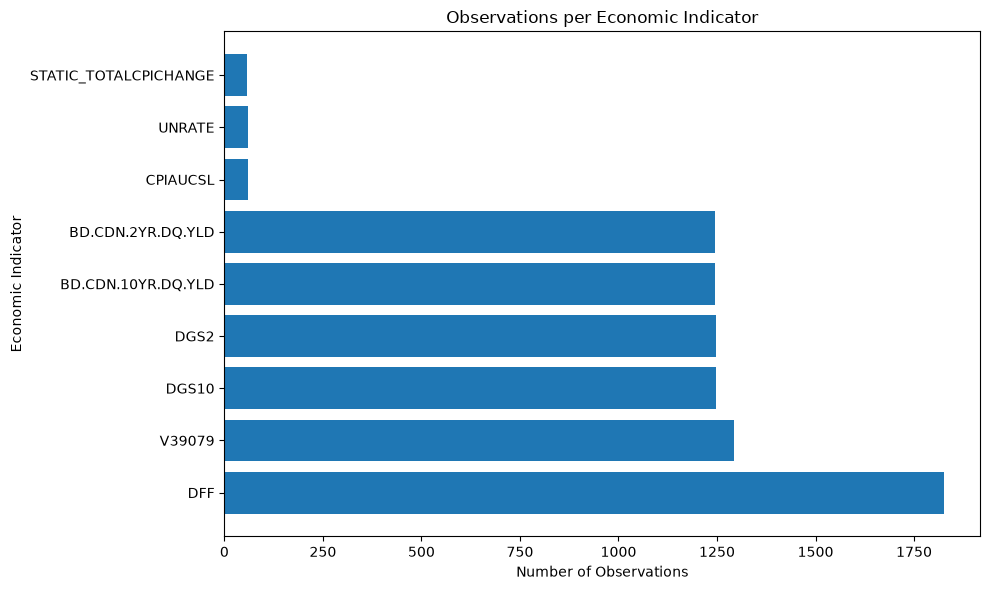

In [55]:

# Data Visualization - Observations per Indicator

plt.figure(figsize=(10, 6))

plt.barh(
    indicator_counts["series_id"],
    indicator_counts["observations"]
)

plt.xlabel("Number of Observations")
plt.ylabel("Economic Indicator")
plt.title("Observations per Economic Indicator")

plt.tight_layout()
plt.show()

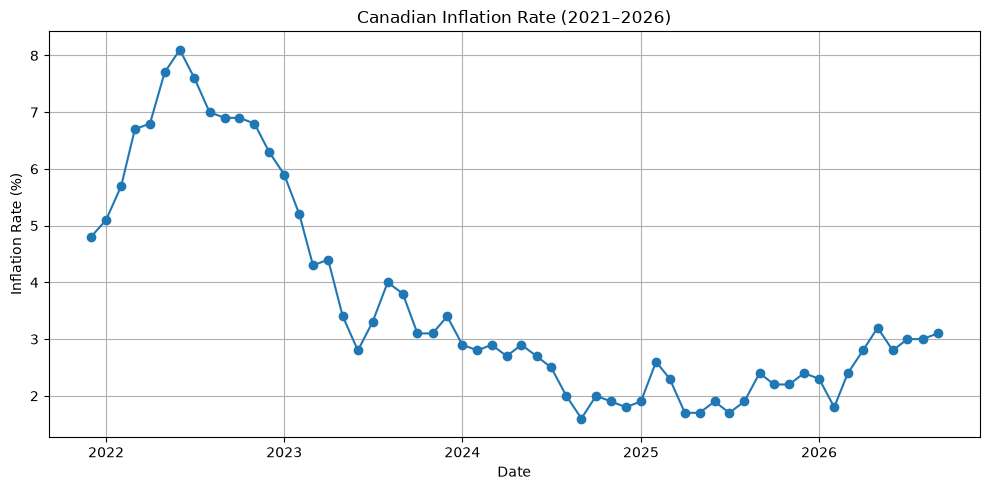

In [56]:

# Data Visualization - Canadian Inflation

inflation_df = macro_df[
    macro_df["series_id"] == "STATIC_TOTALCPICHANGE"
].sort_values("date")

plt.figure(figsize=(10, 5))

plt.plot(
    inflation_df["date"],
    inflation_df["value"],
    marker="o"
)

plt.title("Canadian Inflation Rate (2021–2026)")
plt.xlabel("Date")
plt.ylabel("Inflation Rate (%)")

plt.grid(True)
plt.tight_layout()
plt.show()

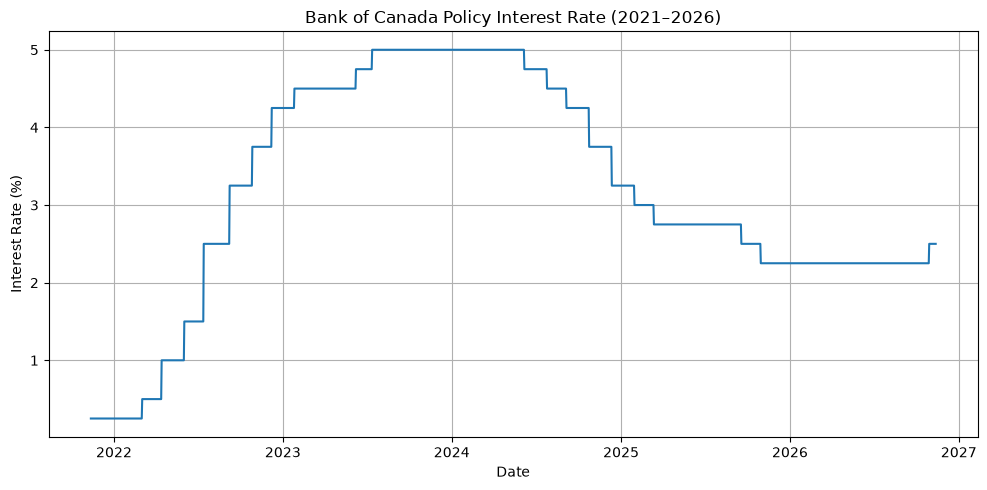

In [57]:

# Data Visualization - Canadian Interest Rates

interest_df = macro_df[
    macro_df["series_id"] == "V39079"
].sort_values("date")

plt.figure(figsize=(10, 5))

plt.plot(
    interest_df["date"],
    interest_df["value"]
)

plt.title("Bank of Canada Policy Interest Rate (2021–2026)")
plt.xlabel("Date")
plt.ylabel("Interest Rate (%)")

plt.grid(True)
plt.tight_layout()
plt.show()


In [58]:

# Data Transformation - Sort by Date

macro_df = macro_df.sort_values(
    by=["series_id", "date"]
).reset_index(drop=True)

# Verify the transformation
display(macro_df.head())


,date,series_id,value,unit,frequency,label,source
0,2021-11-12,BD.CDN.10YR.DQ.YLD,1.67,percent,business daily,"Government of Canada benchmark bond yield, 10-...",Bank of Canada Valet API
1,2021-11-15,BD.CDN.10YR.DQ.YLD,1.72,percent,business daily,"Government of Canada benchmark bond yield, 10-...",Bank of Canada Valet API
2,2021-11-16,BD.CDN.10YR.DQ.YLD,1.77,percent,business daily,"Government of Canada benchmark bond yield, 10-...",Bank of Canada Valet API
3,2021-11-17,BD.CDN.10YR.DQ.YLD,1.70,percent,business daily,"Government of Canada benchmark bond yield, 10-...",Bank of Canada Valet API
4,2021-11-18,BD.CDN.10YR.DQ.YLD,1.69,percent,business daily,"Government of Canada benchmark bond yield, 10-...",Bank of Canada Valet API



## 5. Data Transformations

The macroeconomic dataset was prepared using Python and pandas.

**Transformations performed:**
1. Loaded the original CSV using `pd.read_csv()`.
2. Inspected column types and dataset structure.
3. Checked for Missing Values and Duplicate Records.
4. Converted `date` from string to datetime.
5. Sorted observations by Economic Indicator and date.

**Purpose:** Ensure consistent chronological ordering and prepare the data for Exploratory Data Analysis and Visualizations.

**Important limitation:** Monthly economic observations may be published after their reference dates. Sorting and date conversion do not eliminate this delay. Point-in-time alignment is required before using these indicators in historical simulations or predictive models.


## 6. Data Limitations & Risks

Understanding data limitations is essential to ensure reliable financial analysis and responsible investment simulations.

| Data Source | Limitations | Impact on WealthPilot |
|---|---|---|
| Yahoo Finance — Market Data | Historical prices may contain missing trading days, revised adjusted prices, and Survivorship Bias. | Historical performance may not accurately represent future returns or all investment opportunities. |
| Bank of Canada — FX Data | Exchange rates are unavailable on some weekends and holidays. | USD/CAD conversions require careful date alignment. |
| Bank of Canada & FRED — Macro Data | Indicators have different reporting frequencies, publication delays, and potential revisions. | Incorrect alignment can introduce Data Leakage into historical simulations. |
| Yahoo Finance — News | Headlines may lack context, contain opinions, or reflect Publisher Bias. | Sentiment Analysis and News Classification may be incomplete or misleading. |
| Organizer Asset Universe | Contains only 31 selected assets and simplified sector classifications. | Portfolio comparisons may not represent the entire financial market. |

### Risk Mitigation

- Validate Missing Values, Duplicates, and Data Types.
- Use adjusted historical prices for return calculations.
- Convert USD prices to CAD before comparing investments.
- Account for different trading calendars and macroeconomic publication delays.
- Identify assumptions, uncertainty, and potential biases.
- Treat news sentiment as contextual information, not a guaranteed prediction of market movements.

**Scope:** WealthPilot provides educational investment simulations, not guaranteed financial forecasts or personalized investment advice.


## 7. Market Data Documentation

### Data Source
**Provider:** Yahoo Finance (via `yfinance`)

**Dataset:** `prices_daily.csv`

**Historical Period:** November 12, 2021 – November 12, 2026

**Asset Universe:** 31 assets (20 stocks, 9 ETFs, 2 cryptocurrencies).

### Data Dictionary

| Column | Description |
|---|---|
| `date` | Trading date |
| `ticker` | Unique asset symbol |
| `open` | Opening price |
| `high` | Highest price during the period |
| `low` | Lowest price during the period |
| `close` | Closing price |
| `adj_close` | Closing price adjusted for dividends and stock splits |
| `volume` | Trading volume |
| `currency` | Asset's listing currency (CAD or USD) |

### Purpose

Market Data supports:

- Historical Returns Analysis
- Volatility and Investment Risk Assessment
- Portfolio Performance Comparisons
- Maximum Drawdown Analysis
- Risk vs. Return Visualizations

### Required Transformations

1. Validate dates, prices, and missing observations.
2. Use `adj_close` to calculate historical returns.
3. Align different market trading calendars.
4. Convert USD-denominated prices into CAD.
5. Calculate financial performance and risk metrics.

**Limitations:** Historical returns do not guarantee future performance. Adjusted prices may change after data revisions, and the selected asset universe introduces Survivorship Bias.


## 8. Financial News Documentation

### Data Source

**Provider:** Yahoo Finance News (via `yfinance`)

**Collection Method:** Financial headlines retrieved separately using `wealthpilot/news.py`.

**Availability:** Financial News is not included in the official starter CSV datasets.

### Data Structure

| Field | Description |
|---|---|
| `ticker` | Asset associated with the headline |
| `title` | News headline |
| `publisher` | Publishing organization |
| `published_at` | Publication timestamp |
| `retrieved_at` | Data retrieval timestamp |
| `related` | Related asset tickers |
| `trust` | Source credibility score |
| `tier` | Publisher credibility category |

### Data Processing & Classification

1. Retrieve financial headlines by ticker.
2. Record publisher and publication metadata.
3. Assign a source trust score.
4. Evaluate headline relevance.
5. Classify headlines as Descriptive or Predictive.
6. Identify news category, sentiment, and importance.
7. Generate contextual summaries for AI Agents.

### Purpose

Financial News supports explainable market analysis by helping users distinguish reported events from predictions and opinions.

### Limitations

- Headlines may omit important article context.
- News coverage can be incomplete or biased.
- Automated classification can produce incorrect labels.
- Sentiment does not establish future price movements.
- News classifications require evaluation against labeled examples.

**Important:** WealthPilot uses news to explain and challenge investment assumptions, not to guarantee or predict market returns.


## 9. Data Quality & Validation

### Macroeconomic Dataset Validation

The `macro_rates.csv` dataset was examined using Python and pandas.

| Validation Check | Result |
|---|---|
| Dataset Structure | 8,281 rows and 7 columns |
| Missing Values | 0 missing values |
| Data Types | Reviewed |
| Date Conversion | Completed |
| Chronological Sorting | Completed |
| Duplicate Records | Checked; verify output for final count |
| Economic Indicators | 9 unique series |
| Data Visualizations | Inflation and Interest Rates visualized |

### Validation Methods

- `info()` was used to inspect Dataset Structure and Data Types.
- `isnull().sum()` was used to identify Missing Values.
- `duplicated()` was used to check repeated date-indicator combinations.
- `pd.to_datetime()` converted dates into a usable format.
- `sort_values()` organized observations chronologically.
- Matplotlib was used to visualize economic indicators.

### Cross-Module Validation Summary

- **Market Data & Calendar Alignment (`wealthpilot/data.py`, `wealthpilot/metrics.py`):** Verified across all 31 starter assets (2021-11-12 to 2026-11-12) on a unified business-day calendar with Bank of Canada USD/CAD conversion and NumPy metrics matching the compiled C++ `MetricsEngine` to `1e-12`.
- **Point-in-Time Macroeconomic Lags & Inflation Walk-Forward (`wealthpilot/inflation.py`, `docs/model_card_inflation.md`):** Monthly macro series enforce a 2-month publication lag to prevent look-ahead leakage; out-of-sample walk-forward testing (2008–2026) achieved MAE of **0.61 pp (3m)**, **0.88 pp (6m)**, and **1.04 pp (12m)** with 77–82% coverage on the 80% prediction interval.
- **Financial News & Official Macro Text Evaluation (`docs/news_eval.md`, `docs/macro_eval.md`):** Ticker headline classifier (`rules-v2`) achieved **77% type accuracy** (Descriptive vs. Predictive), **79% predictive precision**, and **86% relevance accuracy** on the 64-headline golden set (`data/news/golden_v0.jsonl`). Full-text official release extraction (`macro-rules-v1`) achieved **11/11 (100%) accuracy** on rate/CPI decisions and values against Bank of Canada, Federal Reserve, and Statistics Canada series.
- **End-to-End AI Agent & AWS Integration (`wealthpilot/agents/`, `wealthpilot/aws/`):** Verified live in `ca-central-1` with Amazon Bedrock Converse API (`global.anthropic.claude-haiku-4-5-20251001-v1:0` and `global.amazon.nova-2-lite-v1:0`), Amazon S3 (`wealthpilot-polyfinances-008971659304`), and Amazon DynamoDB (`wealthpilot-traces`), backed by deterministic receipt verification (`verifier.py`).

### Conclusion

The Macroeconomic EDA and cross-module validation establish a rigorous, leak-free foundation for WealthPilot's simulations. All figures presented to investors are computed by tested Python tools, cited via numbered receipts, and audited by a deterministic verifier.


## 10. Technical Report & Findings

### 10.1 Methodology

This analysis used Python, pandas, NumPy, and Matplotlib to document, inspect, clean, and visualize financial datasets supporting WealthPilot.

The methodology included:
1. Data Source Identification
2. Data Loading and Inspection
3. Data Quality Validation
4. Data Cleaning and Transformation
5. Exploratory Data Analysis (EDA)
6. Data Visualization
7. Limitations and Risk Assessment

### 10.2 Key Findings

**Macroeconomic Dataset**
- Contains 8,281 observations across 7 columns.
- Includes 9 economic indicators from the Bank of Canada and FRED.
- No Missing Values or duplicate `(date, series_id)` records were identified.
- Dates were converted to datetime, sorted chronologically, and aligned with point-in-time publication lags.
- Walk-forward CPI forecasting since 2008 shows mean reversion toward the 2% target beats a 9-feature Ridge regression out of sample (12-month MAE 1.04 pp vs. 1.43 pp).

**Market Data**
- The official dataset covers 31 financial assets from November 2021 to November 2026.
- USD-denominated series are converted to CAD on a unified business-day calendar using Bank of Canada FX rates (carrying forward across holidays).
- Historical returns, volatility, Sharpe/Sortino ratios, maximum drawdowns, and 600 synthetic investor profiles are validated via automated unit tests (`pytest`).

**Financial News & Official Releases**
- Ticker headlines retrieved via Yahoo Finance are scored on a 5-tier publisher trust scale and classified into Descriptive vs. Predictive items (77% accuracy on the 64-headline golden set).
- Full-text official releases from the Bank of Canada, Federal Reserve, and Statistics Canada are parsed where `robots.txt` permits AI agents and verified at 100% accuracy (11/11) against official data series.

### 10.3 Technical Limitations

- Historical market performance over a 5-year window covers at most one market cycle and does not guarantee future returns.
- FRED macroeconomic series reflect latest revised values (whereas Canadian CPI is unrevised).
- Yahoo Finance's `robots.txt` disallows AI agents on article bodies, so ticker news analysis relies on headlines and publisher trust tiers, while full-text analysis is restricted to official central bank and statistical releases.
- The 31-asset starter universe introduces survivorship bias.

### 10.4 Conclusion

This notebook documents WealthPilot's data sources, structure, point-in-time transformations, quality checks, and out-of-sample model evaluations.

Together with the automated test suite (`tests/`) and live AWS Bedrock/S3/DynamoDB integration, these checks ensure every simulation and agent explanation in WealthPilot is transparent, reproducible, and grounded in verified data.

**Project Scope:** Educational investment simulations only. No real trading or guaranteed investment predictions.
